In [11]:
import h5py

def print_structure(name, obj):
    print(name)

with h5py.File('./Data/CDM/snapshot_000.hdf5', 'r') as f:
    f.visititems(print_structure)

Config
Header
Parameters
PartType1
PartType1/CCPTime
PartType1/Coordinates
PartType1/Masses
PartType1/ParticleIDs
PartType1/SubhaloIDs
PartType1/Velocities


In [12]:
import h5py
import glob
import numpy as np

# 1. Define the path pattern
sim_dir = './Data/CDM/'
file_pattern = sorted(glob.glob(f"{sim_dir}snapshot_[0-9][0-9][0-9].hdf5"))

all_pos = []
all_mass = []

# 2. Loop and extract
for file in file_pattern:
    with h5py.File(file, 'r') as f:
        # Accessing PartType1 as per your reference code
        # .get() prevents crashing if a specific file is missing a dataset
        pos = f.get('PartType1/Coordinates')
        mass = f.get('PartType1/Masses')
        
        if pos is not None and mass is not None:
            all_pos.append(pos[:])
            all_mass.append(mass[:])

# 3. Convert to final numpy arrays
pos_array = np.array(all_pos)
mass_array = np.array(all_mass)

print(f"Loaded {len(pos_array)} snapshots.")
print(f"Shape of positions: {pos_array.shape}") # (Snapshots, Particles, 3)

Loaded 281 snapshots.
Shape of positions: (281, 41212, 3)


281 valid AHF centers collected.
{0: array([10682.10081878,  9999.93722797, 10000.01734354]), 1: array([10681.76325586, 10001.70234229,  9999.9768719 ]), 2: array([10680.95493902, 10003.39301817, 10000.00084653]), 3: array([10679.54554558, 10005.0271074 ,  9999.98630087]), 4: array([10677.43475592, 10006.74624561,  9999.97382747]), 5: array([10674.79522006, 10008.33686676, 10000.07598493]), 6: array([10671.7887073 , 10009.83515243, 10000.05374455]), 7: array([10667.92435116, 10011.54432694,  9999.94914105]), 8: array([10663.48548581, 10013.11965222, 10000.01729394]), 9: array([10658.79765838, 10014.92437421, 10000.01021188]), 10: array([10653.14118109, 10016.33811491, 10000.07619512]), 11: array([10647.22196635, 10017.81232217,  9999.93721457]), 12: array([10640.2729941 , 10019.44080694, 10000.01818457]), 13: array([10632.83878999, 10021.1844407 , 10000.02001878]), 14: array([10625.22101189, 10022.58403456,  9999.97043503]), 15: array([10616.47270676, 10024.25626109, 10000.05701297]), 

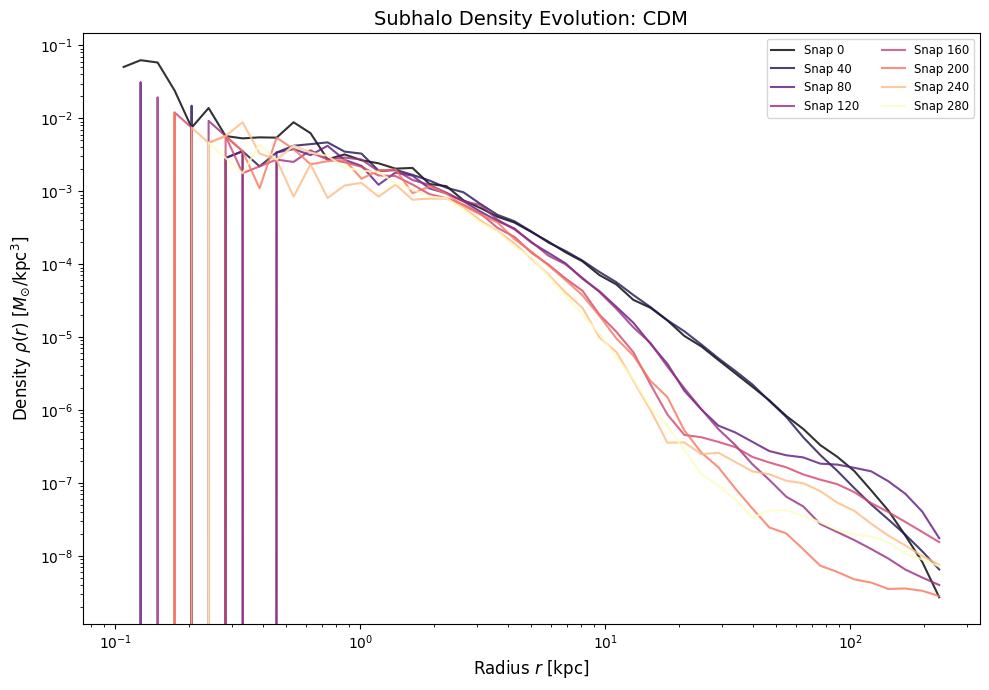

In [ ]:
import os
import h5py
import numpy as np
import matplotlib.pyplot as plt

# ==================== CONFIGURATION ====================
AHF_DIR = "./Data/CDM_AHFout/"
SNAP_DIR = "./Data/CDM/"
SNAPSHOT_INTERVAL = 300
TOTAL_SNAPS = 280

# Fixed Radial Grid Parameters
R_MIN, R_MAX, N_BINS = 0.1, 250.0, 50

# ==================== 1. PRE-COLLECT CENTERS ====================
print("Collecting AHF centers...")
all_centers = {}
# Loop through potential snapshot range to find valid subhalo entries
for i in range(TOTAL_SNAPS + 1):
    path = os.path.join(AHF_DIR, f"{i}-halos")
    if os.path.exists(path):
        with open(path, 'r') as f:
            lines = f.readlines()
            if len(lines) > 1:
                # Assuming index 1 is the first subhalo in the AHF file
                cols = lines[1].split()
                raw_pos = np.array([float(cols[5]), float(cols[6]), float(cols[7])])
                all_centers[i] = raw_pos
print(len(all_centers), "valid AHF centers collected.")
print(all_centers)

aval_snap = np.linspace(0, len(all_centers)-1, len(all_centers), dtype=int)

# Filter indices based on your interval within the valid subhalo lifetime
indices_to_process = [i for i in aval_snap if i % SNAPSHOT_INTERVAL == 0]
print(indices_to_process)

# ==================== 2. SETUP GRID & FUNCTIONS ====================
bins = np.logspace(np.log10(R_MIN), np.log10(R_MAX), N_BINS)
bin_centers = np.sqrt(bins[1:] * bins[:-1])  # Geometric mean for log-bins
v_shells = (4/3) * np.pi * (bins[1:]**3 - bins[:-1]**3)

def calc_density(pos, mass, center):
    """Calculates density profile for a single snapshot."""
    r = np.sqrt(np.sum((pos - center)**2, axis=1))
    mass_in_bin, _ = np.histogram(r, bins=bins, weights=mass)
    return mass_in_bin / v_shells

# ==================== 3. MAIN PROCESSING LOOP ====================
density_list = []
processed_snaps = []

print(f"Processing {len(indices_to_process)} snapshots...")
for i in indices_to_process:
    snap_path = os.path.join(SNAP_DIR, f"snapshot_{i:03d}.hdf5")
    
    if os.path.exists(snap_path):
        with h5py.File(snap_path, 'r') as f:
            # Adjust PartType1 if your particles are in a different group
            pos = f['PartType1/Coordinates'][:]
            mass = f['PartType1/Masses'][:]
            
        rho = calc_density(pos, mass, all_centers[i])
        density_list.append(rho)
        processed_snaps.append(i)
        print(f"  Snapshot {i:03d} completed.", end='\r')

# ==================== 4. PLOTTING ====================
plt.figure(figsize=(10, 7))
cmap = plt.get_cmap('magma')

for idx, rho in enumerate(density_list):
    snap_num = processed_snaps[idx]
    # Color scale normalized to the full simulation duration
    color_val = snap_num / TOTAL_SNAPS
    plt.loglog(bin_centers, rho, color=cmap(color_val), 
               label=f'Snap {snap_num}', alpha=0.8, lw=1.5)

plt.xlabel(r'Radius $r$ [kpc]', fontsize=12)
plt.ylabel(r'Density $\rho(r)$ [$M_{\odot}/\mathrm{kpc}^3$]', fontsize=12)
plt.title(f'Subhalo Density Evolution: {SNAP_DIR.split("/")[-2]}', fontsize=14)
plt.legend(ncol=2, fontsize='small', loc='upper right')
plt.tight_layout()
plt.show()

144 valid AHF centers collected.
{0: array([10682.10081878,  9999.93722797, 10000.01734354]), 1: array([10681.84387835, 10001.65550392, 10000.05705259]), 2: array([10681.05745575, 10003.29689271, 10000.13462011]), 3: array([10679.52914383, 10005.13314294, 10000.00083628]), 4: array([10677.46567964, 10006.56800809, 10000.15439781]), 5: array([10675.02482002, 10008.19126765, 10000.00650785]), 6: array([10671.78133691, 10009.86849121, 10000.06885418]), 7: array([10668.10755059, 10011.53601954, 10000.00939704]), 8: array([10663.48253764, 10013.11479471, 10000.00851582]), 9: array([10658.4581307 , 10014.98634222, 10000.30442836]), 10: array([10653.12258343, 10016.5125016 ,  9999.97776391]), 11: array([10647.01968413, 10018.21552004, 10000.00128268]), 12: array([10640.8561321 , 10019.54682849,  9999.79537996]), 13: array([10633.54048636, 10021.00583795, 10000.0285096 ]), 14: array([10625.32049417, 10022.13842135, 10000.01016259]), 15: array([10616.77737887, 10023.78466139, 10000.39060432]), 

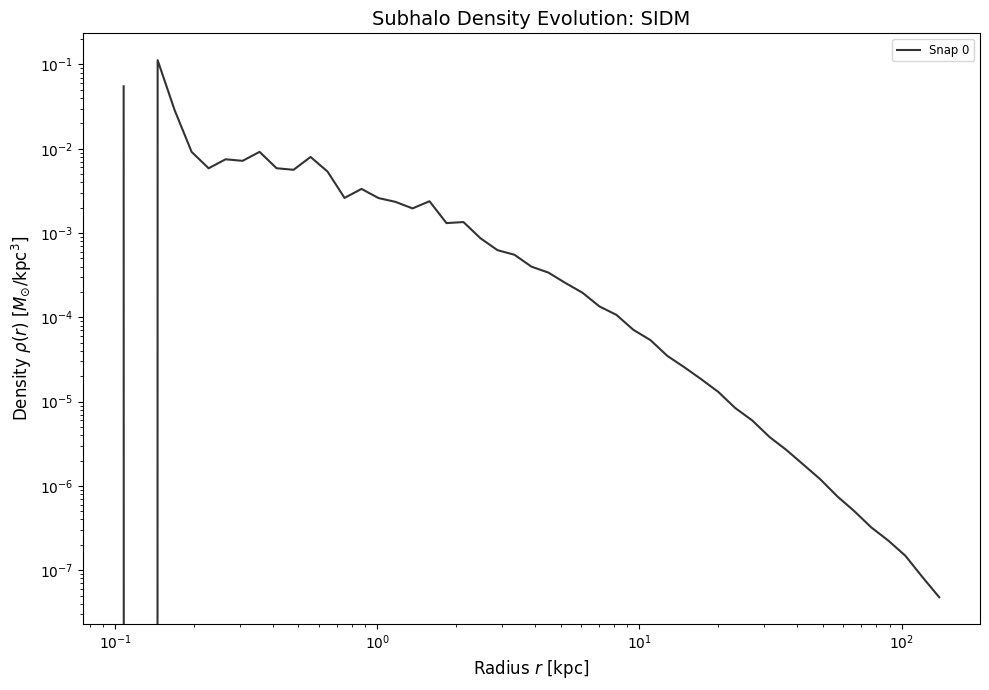

In [4]:
import os
import h5py
import numpy as np
import matplotlib.pyplot as plt

# ==================== CONFIGURATION ====================
AHF_DIR = "./Data/SIDM_AHFout/"
SNAP_DIR = "./Data/SIDM/"
SNAPSHOT_INTERVAL = 300
TOTAL_SNAPS = 280

# Fixed Radial Grid Parameters
R_MIN, R_MAX, N_BINS = 0.1, 150.0, 50

# ==================== 1. PRE-COLLECT CENTERS ====================
print("Collecting AHF centers...")
all_centers = {}
# Loop through potential snapshot range to find valid subhalo entries
for i in range(TOTAL_SNAPS + 1):
    path = os.path.join(AHF_DIR, f"{i}-halos")
    if os.path.exists(path):
        with open(path, 'r') as f:
            lines = f.readlines()
            if len(lines) > 1:
                # Assuming index 1 is the first subhalo in the AHF file
                cols = lines[1].split()
                raw_pos = np.array([float(cols[5]), float(cols[6]), float(cols[7])])
                all_centers[i] = raw_pos
print(len(all_centers), "valid AHF centers collected.")
print(all_centers)

aval_snap = np.linspace(0, len(all_centers)-1, len(all_centers), dtype=int)

# Filter indices based on your interval within the valid subhalo lifetime
indices_to_process = [i for i in aval_snap if i % SNAPSHOT_INTERVAL == 0]
print(indices_to_process)

# ==================== 2. SETUP GRID & FUNCTIONS ====================
bins = np.logspace(np.log10(R_MIN), np.log10(R_MAX), N_BINS)
bin_centers = np.sqrt(bins[1:] * bins[:-1])  # Geometric mean for log-bins
v_shells = (4/3) * np.pi * (bins[1:]**3 - bins[:-1]**3)

def calc_density(pos, mass, center):
    """Calculates density profile for a single snapshot."""
    r = np.sqrt(np.sum((pos - center)**2, axis=1))
    mass_in_bin, _ = np.histogram(r, bins=bins, weights=mass)
    return mass_in_bin / v_shells

# ==================== 3. MAIN PROCESSING LOOP ====================
density_list = []
processed_snaps = []

print(f"Processing {len(indices_to_process)} snapshots...")
for i in indices_to_process:
    snap_path = os.path.join(SNAP_DIR, f"snapshot_{i:03d}.hdf5")
    
    if os.path.exists(snap_path):
        with h5py.File(snap_path, 'r') as f:
            # Adjust PartType1 if your particles are in a different group
            pos = f['PartType1/Coordinates'][:]
            mass = f['PartType1/Masses'][:]
            
        rho = calc_density(pos, mass, all_centers[i])
        print(rho)
        density_list.append(rho)
        processed_snaps.append(i)
        print(f"  Snapshot {i:03d} completed.", end='\r')

# ==================== 4. PLOTTING ====================
plt.figure(figsize=(10, 7))
cmap = plt.get_cmap('magma')

for idx, rho in enumerate(density_list):
    snap_num = processed_snaps[idx]
    # Color scale normalized to the full simulation duration
    color_val = snap_num / TOTAL_SNAPS
    plt.loglog(bin_centers, rho, color=cmap(color_val), 
               label=f'Snap {snap_num}', alpha=0.8, lw=1.5)

plt.xlabel(r'Radius $r$ [kpc]', fontsize=12)
plt.ylabel(r'Density $\rho(r)$ [$M_{\odot}/\mathrm{kpc}^3$]', fontsize=12)
plt.title(f'Subhalo Density Evolution: {SNAP_DIR.split("/")[-2]}', fontsize=14)
plt.legend(ncol=2, fontsize='small', loc='upper right')
plt.tight_layout()
plt.show()

Processing CDM...
Processing SIDM...


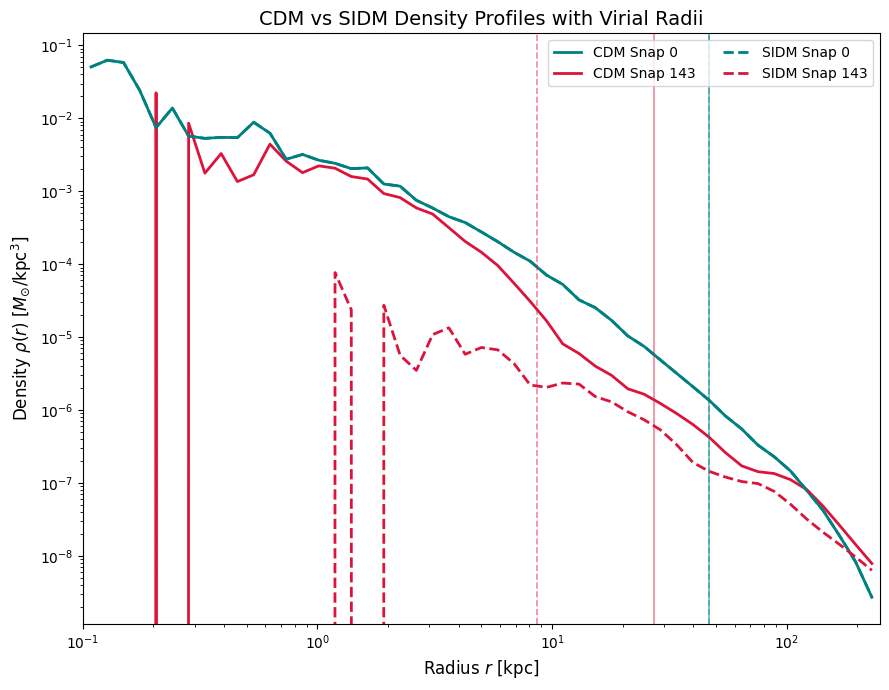

In [15]:
import os
import h5py
import numpy as np
import matplotlib.pyplot as plt

# ==================== CONFIGURATION ====================
BASE_DIR = "./Data/"
SIMS = {
    "CDM": {"snap": "CDM/", "ahf": "CDM_AHFout/", "ls": "-"},
    "SIDM": {"snap": "SIDM/", "ahf": "SIDM_AHFout/", "ls": "--"}
}
TARGET_SNAPS = [0, 143]
COLORS = {0: "teal", 143: "crimson"}

# Fixed Radial Grid
R_MIN, R_MAX, N_BINS = 0.1, 250.0, 50
bins = np.logspace(np.log10(R_MIN), np.log10(R_MAX), N_BINS)
bin_centers = np.sqrt(bins[1:] * bins[:-1])
v_shells = (4/3) * np.pi * (bins[1:]**3 - bins[:-1]**3)

# ==================== FUNCTIONS ====================
def get_ahf_data(ahf_path, snap_idx):
    """Reads center and radius (12th col) for a specific snapshot."""
    file_path = os.path.join(ahf_path, f"{snap_idx}-halos")
    if not os.path.exists(file_path): return None, None
    with open(file_path, 'r') as f:
        lines = f.readlines()
        if len(lines) <= 1: return None, None
        cols = lines[1].split()
        center = np.array([float(cols[5]), float(cols[6]), float(cols[7])])
        radius = float(cols[11]) # 12th element
        return center, radius

def get_density(snap_path, snap_idx, center):
    """Reads HDF5 and calculates density."""
    file_path = os.path.join(snap_path, f"snapshot_{snap_idx:03d}.hdf5")
    if not os.path.exists(file_path): return None
    with h5py.File(file_path, 'r') as f:
        pos = f['PartType1/Coordinates'][:]
        mass = f['PartType1/Masses'][:]
    
    r = np.sqrt(np.sum((pos - center)**2, axis=1))
    mass_in_bin, _ = np.histogram(r, bins=bins, weights=mass)
    return mass_in_bin / v_shells

# ==================== MAIN PROCESSING & PLOT ====================
plt.figure(figsize=(9, 7))

for label, paths in SIMS.items():
    print(f"Processing {label}...")
    ahf_full_path = os.path.join(BASE_DIR, paths["ahf"])
    snap_full_path = os.path.join(BASE_DIR, paths["snap"])
    
    for s_idx in TARGET_SNAPS:
        center, r_vir = get_ahf_data(ahf_full_path, s_idx)
        if center is None: continue
            
        rho = get_density(snap_full_path, s_idx, center)
        if rho is None: continue

        # 1. Plot the Density Profile
        line_label = f"{label} Snap {s_idx}"
        plt.loglog(bin_centers, rho, 
                   color=COLORS[s_idx], 
                   linestyle=paths["ls"], 
                   label=line_label, 
                   lw=2)

        # 2. Plot the Vertical Line for Radius
        # Using alpha=0.5 so they don't clutter the background too much
        plt.axvline(x=r_vir, 
                    color=COLORS[s_idx], 
                    linestyle=paths["ls"], 
                    alpha=0.5, 
                    lw=1.2)

# Formatting
plt.xlabel(r'Radius $r$ [kpc]', fontsize=12)
plt.ylabel(r'Density $\rho(r)$ [$M_{\odot}/\mathrm{kpc}^3$]', fontsize=12)
plt.title('CDM vs SIDM Density Profiles with Virial Radii', fontsize=14)
plt.legend(loc='upper right', ncol=2)
plt.xlim(R_MIN, R_MAX) # Ensure plot boundaries match your grid
plt.tight_layout()

plt.show()

In [16]:
import h5py
import glob
import numpy as np

file_path = "./Data/SIDM_AHFout/"
filename="0-halos"

center=[]

with open(file_path+filename, "r") as file:
            next(file)
            first_line = file.readline()
            second_line = first_line.strip().split()
            center = [float(second_line[5]), float(second_line[6]), float(second_line[7])]

print(center)

[10682.10081878, 9999.93722797, 10000.01734354]


In [17]:
R_MIN = 0.1
R_MAX = 150.0
N_BINS = 50

bins = np.logspace(np.log10(R_MIN), np.log10(R_MAX), N_BINS)
bin_centers = np.sqrt(bins[1:] * bins[:-1])  # Geometric mean for log-bins

# print(bins[1:])
# print(bins[:-1])

In [18]:
def calc_density(vel, pos, mass, center):
    vol = (4/3) * np.pi * (bins[1:]**3 - bins[:-1]**3)
    print(vol)